<a href="https://colab.research.google.com/github/ctobar96/ClasificacionTerreno/blob/main/notebooks/01_eda_eurosat.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div>
<img src="https://i.ibb.co/v3CvVz9/udd-short.png" width="150"/>
    <br>
    <strong>Universidad del Desarrollo</strong><br>
    <em>Magíster en Data Science</em><br>
    <em>Profesor: Takeshi Asahi Kodama</em><br>

</div>

# **<center>SISTEMA DE CLASIFICACIÓN DE IMÁGENES</center>**

**Nombre Estudiante**: Cristian Tobar Morales  
**Asignatura**: Visión Computacional

## **TABLA DE CONTENIDO**

01. Introducción
02.	Objetivo
03.	Metodología
04.	Descripción de la base de datos
05.	Desarrollo
    *   Carga y análisis exploratorio
        -   Librerías requeridas
        -	Información inicial del dataset
        -	Ingreso de los datos
        -	Visualización
    *	Dataset de entrenamiento y prueba
    *	Preprocesamiento de los datos
        -	Normalización
        -	Aumento de datos    
        -	Eliminar ruido
    *	Convertir el generador
    *	Redes neuronales Convolucionales
        -	Creación y compilación del modelo
06.	Análisis del desempeño de los modelos
07.	Conclusiones

## **01. INTRODUCCIÓN**
El presente informe detalla una base de datos correspondiente a imágenes de cobertura terrestre, con el fin del preprocesamiento la cual cuenta con diferentes coberturas en sus datos.

La base de datos fue obtenida de la plataforma en línea [Kaggle][DataSet], la cual se especializa en ciencia de datos y Machine Learning.

Este conjunto de datos corresponde a imágenes de cobertura terrestre registradas por el satélite Sentinel-2, diseñado para la clasificación de tipos de suelo y aplicaciones de teledetección. El registro cuenta con 10 clases distintas de cobertura.

[DataSet]: https://www.kaggle.com/datasets/salmaadell/eurosat-rgb


## **02. OBJETIVO**
Desarrollar un sistema de procesamiento y análisis de imágenes, para realizar mediciones.

## **03. METODOLOGÍA**
-	**Carga y análisis exploratorio de los datos**  
Se ingresan los datos crudos para observar la resolución que poseen, se toma con referencia la primera imagen de cada clase de terreno.
-	**Dataset de entrenamiento y prueba**  
Se divide el conjunto total de imágenes de modo que el 80% de ellas se utilicen para ajustar el modelo, y el 20% restante para evaluar la capacidad de generalización del mismo.
-	**Preprocesamiento de los datos**  
Se realiza para transformar los datos crudos en una forma que sea mas adecuada para ser ingresadas el modelo.
-	**Convertir el generador**   
Para obtener X_train, y_train, X_test y y_test de tus generadores de datos train_dataset y test_dataset.
-	**Redes neuronales convolucionales**    
-	**Análisis de desempeño**  
Se evalúa el desempeño del modelo de clasificación, mediante la precisión, recall y F1-score.


## **04. DESCRIPCIÓN DE LA BASE DE DATOS**
El dataset contiene imágenes de cobertura terrestres registradas por el satélite Sentinel-2, diseñados para la clasificación de tipos de suelo y aplicaciones de teledetección. La base de datos contiene un conjunto de diez clases distintas de cobertura.

Los terrenos que cubre:
-	**Bosque (Forest):** Áreas densamente arboleadas, incluidos bosques naturales y plantaciones.
-	**Residencial (Residential):** Regiones urbanas y suburbanas con casas, edificios y asentamientos.  
-	**Vegetación Herbácea (Herbaceous Vegetation):** Pastizales, arbustos y plantas no leñosas.
-	**Mar/Lago (Sea/Lake):** Grandes masa de agua, incluidos mares, lagos y océanos.
-	**Cultivo Anual (Annual Crop):** Tierras de cultivo, con cultivos desde que se planta y cosechan en un solo año.
-	**Industrial:** Áreas con fábricas, almacenes e instalaciones de fabricación.
-	**Río (River):** Cuerpos de agua que fluyen, como ríos y arroyos.
-	**Autopista (Highway):** Carreteras principales, autopistas y rutas de transporte.
-	**Cultivo permanente (Permanent Crop):** Terrenos con cultivo que crecen de forma continua, como viñedos y huertos.
-	**Pastizales (Pasture):** Pastizales utilizados para el pastoreo del ganado.

## **05. DESARROLLO**

### **CARGA Y ANÁLISIS EXPLORATORIO DE LOS DATOS**

#### Librerías requeridas

In [21]:
from google.colab import drive
drive.mount('/content/drive')

# Directorio base del proyecto
BASE_DIR = '/content/drive/MyDrive/ClasificacionTerreno'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, UnidentifiedImageError, ImageFilter
from IPython.display import display
from scipy.ndimage import gaussian_filter
from sklearn.model_selection import train_test_split

# TensorFlow y Keras
import tensorflow as tf
import tensorflow_datasets as tfds
from tensorflow.io import parse_single_example, FixedLenFeature
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization, SpatialDropout2D
from tensorflow.keras.regularizers import l2

In [8]:
# Habilitar el crecimiento de memoria dinámico (Imprescindible si usas GPU)
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print("Crecimiento dinámico de memoria GPU activado.")
    except RuntimeError as e:
        print(e)

Physical devices cannot be modified after being initialized


#### Información inicial del dataset

In [22]:
ruta_tfrecord = f'{BASE_DIR}/data/eurosat-train.tfrecord-00000-of-00001'

# Definir la descripción de las características basándose en el TFRecord
feature_description = {
    'image': tf.io.FixedLenFeature([], tf.string),
    'label': tf.io.FixedLenFeature([], tf.int64)
}

def _parse_function(example_proto):
    parsed_features = tf.io.parse_single_example(example_proto, feature_description)
    image = tf.io.decode_png(parsed_features['image'], channels=3)
    label = parsed_features['label']
    return image, label

# 1. Lectura y descompresión: se aplica el .map aquí
parsed_dataset = tf.data.TFRecordDataset(ruta_tfrecord).map(_parse_function)

try:
    # 2. Iteración: se utiliza el dataset ya procesado sin volver a usar .map()
    for image, label in parsed_dataset.take(1):
        forma_imagen = image.shape
        tipo_dato = image.dtype

    print("\033[1mINFORMACIÓN GENERAL DE IMÁGENES (Leída del TFRecord)\033[0m")
    print(f"- Dimensiones (Shape): {forma_imagen} -> (Alto, Ancho, Canales RGB)")
    print(f"- Tipo de dato: {tipo_dato}")

except Exception as e:
    print(f"Error al leer el dataset principal: {e}")

INFORMACIÓN GENERAL DE IMÁGENES (Leída del TFRecord)
- Dimensiones (Shape): (64, 64, 3) -> (Alto, Ancho, Canales RGB)
- Tipo de dato: <dtype: 'uint8'>


Las imágenes están codificadas en formato `PNG`, con dimensiones `[64, 64, 3]`, correspondientes al ancho, alto y número de canales de color, respectivamente. Por lo tanto, cada imagen tiene una resolución de **64 × 64 píxeles** y utiliza el espacio de color **RGB**.

Los tres canales de color corresponden a:

* **Canal 1 → Rojo (R)**
* **Canal 2 → Verde (G)**
* **Canal 3 → Azul (B)**


In [23]:
# Ruta actualizada para tu Google Drive en Colab
label_path = f'{BASE_DIR}/data/label.labels.txt'

with open(label_path, 'r') as f:
    label_names = f.read().splitlines()

print("\033[1mLISTA DE ETIQUETAS\033[0m")
print(f'Cantidad: {len(label_names)}\n')
print("\n".join(label_names))

LISTA DE ETIQUETAS
Cantidad: 10

AnnualCrop
Forest
HerbaceousVegetation
Highway
Industrial
Pasture
PermanentCrop
Residential
River
SeaLake


El conjunto de datos contiene **10 etiquetas o clases**, correspondientes a diferentes tipos de cobertura y uso del suelo:

1. **AnnualCrop** → Cultivos anuales
2. **Forest** → Bosque
3. **HerbaceousVegetation** → Vegetación herbácea
4. **Highway** → Carretera o autopista
5. **Industrial** → Zona industrial
6. **Pasture** → Pastizal
7. **PermanentCrop** → Cultivos permanentes
8. **Residential** → Zona residencial
9. **River** → Río
10. **SeaLake** → Mar o lago

#### Ingreso de los datos

#### Visualización
Se imprime una imagen por cada clase de terreno, con el objetivo de observar los archivos entregados para dicho estudio.

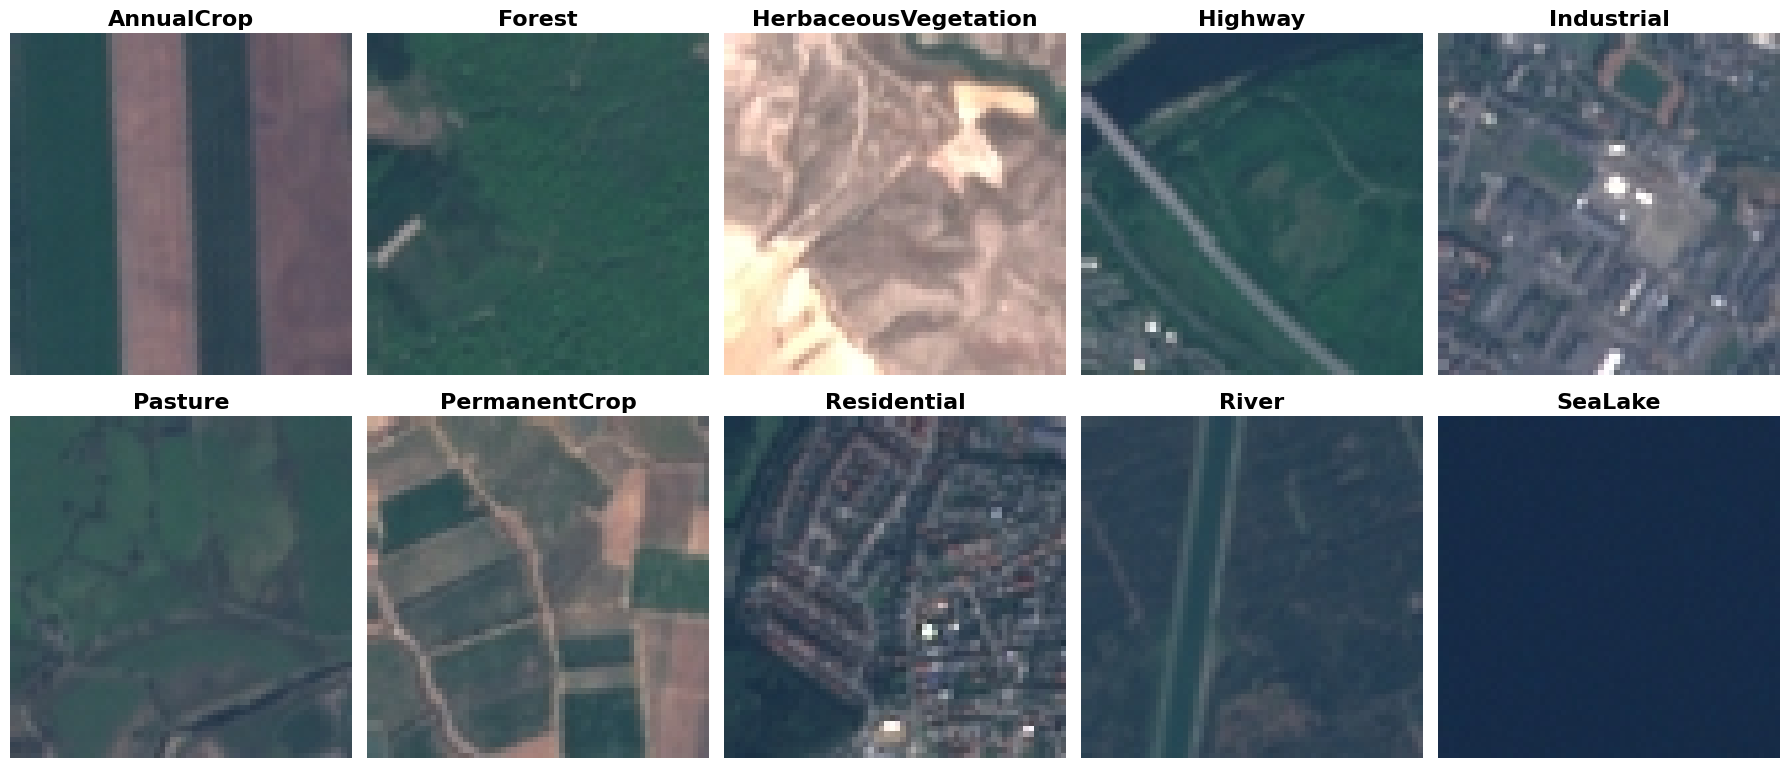

In [11]:
label_names = [
    "AnnualCrop",
    "Forest",
    "HerbaceousVegetation",
    "Highway",
    "Industrial",
    "Pasture",
    "PermanentCrop",
    "Residential",
    "River",
    "SeaLake"
]

# Función para visualizar una imagen de ejemplo por cada terreno
def visualizar_img(data):

    """
    Visualiza una imagen representativa para cada tipo de terreno.
    Se espera que 'data' sea un dataset de TensorFlow que devuelva pares (image, label),
    y que 'label_names' sea una lista global con el nombre de las etiquetas.
    """

    # Diccionario para almacenar una imagen representativa para cada etiqueta numérica.
    images_by_type = {}

    # Iterar sobre el dataset para recolectar una imagen representativa para cada etiqueta númerica
    for image, label in data:
        nombre = label.numpy() # Obtener el entero de la etiqueta

        # Condicional para el caso que no este guardada la img
        if nombre not in images_by_type:
            # Convertimos el tensor de imagen a un array de NumPy para Matplotlib
            images_by_type[nombre] = image.numpy()

        # Si ya tenemos una img por cada clase, detenemos la iteración
        if len(images_by_type) == len(label_names):
            break

    # Número total de clases
    num_classes = len(label_names)

    # Definir la grilla; por ejemplo, para 10 clases puedes usar 2 filas y 5 columnas
    rows = 2
    cols = num_classes // rows

    plt.figure(figsize=(18, 8))
    for i in range(num_classes):
        try:
            plt.subplot(rows, cols, i+1)
            # Mostrar la imagen almacenada para la clase i
            # (Se asume que los valores de los píxeles están entre 0-255 o 0-1)
            plt.imshow(images_by_type[i])
            # Título usando el nombre textual de la clase
            plt.title(label_names[i], fontsize=16, fontweight='bold')
            plt.axis('off') # Quitar los ejes
        except Exception as e:
            print(f"Error al mostrar la imagen '{label_names[i]}': {e}")

    plt.tight_layout() # Ajustar espacio entre imágenes
    plt.show() # imprimir img

# Ejecutar función (AQUÍ ESTÁ LA CORRECCIÓN CLAVE)
# Asegúrate de usar el nombre de tu función de parseo real si es distinto a _parse_function
# 1. Creamos una conexión limpia y directa a tus datos usando la variable correcta
dataset_visualizacion = tf.data.TFRecordDataset(ruta_tfrecord).map(_parse_function)

# 2. Ejecutamos tu función con estos datos frescos
visualizar_img(dataset_visualizacion)

### **DATASET DE ENTRENAMIENTO Y PRUEBA (80% TRAIN Y 20% TEST)**
Se divide el conjunto total de imágenes de modo que el 80% de ellas se utilicen para ajustar el modelo, y el 20% restante para evaluar la capacidad de generalización del mismo.
-	**Entrenamiento:** Se utilizar para que el modelo aprenda patrones y características de las imágenes.

-	**Test:** Se utiliza para evaluar el desempeño del modelo en datos no conocidos, esto nos permite medir la capacidad del modelo para generalizar y detectar posibles problemas.


In [12]:
# Obtener la cantidad total de datos
total_count = parsed_dataset.reduce(tf.constant(0), lambda counter, _: counter + 1).numpy()
print("Total de muestras:", total_count)

Total de muestras: 27000


In [13]:
# Definir los tamaños
DATASET_SIZE = total_count
TRAIN_SIZE = int(0.7 * DATASET_SIZE)
VAL_SIZE = int(0.15 * DATASET_SIZE)
TEST_SIZE = DATASET_SIZE - TRAIN_SIZE - VAL_SIZE

# Asegurar de mezclar el dataset antes de dividirlo
shuffled_dataset = parsed_dataset.shuffle(buffer_size=total_count, reshuffle_each_iteration=False)

# Extraer el conjunto de entrenamiento
train_ds = shuffled_dataset.take(TRAIN_SIZE)

# Obtener lo que sobreante para validación y prueba
remaining_dataset = shuffled_dataset.skip(TRAIN_SIZE)

# Dividir el conjunto restante en validación y prueba
val_ds = remaining_dataset.take(VAL_SIZE)
test_ds = remaining_dataset.skip(VAL_SIZE)

print ("-"*20, "DIVISIÓN DE DATOS", "-"*20)
print(f"Dataset completo: {DATASET_SIZE}")
print(f"Entrenamiento:    {TRAIN_SIZE}")
print(f"Validación:       {VAL_SIZE}")
print(f"Prueba:            {TEST_SIZE}")


-------------------- DIVISIÓN DE DATOS --------------------
Dataset completo: 27000
Entrenamiento:    18900
Validación:       4050
Prueba:            4050


### **PREPROCESAMIENTO DE LOS DATOS**
Se realiza para transformar los datos crudos en una forma que sea mas adecuada para ser ingresadas el modelo.
Mediante la normalización, aumento de datos y eliminar el ruido permite:
- Uniformidad de los datos
- Incrementar la cantidad y variedad.
- Mejorar la calidad de la visualización y reducir interferencias.


#### Normalización
- **Qué es:** Dividir los valores de los píxeles (que van de 0 a 255) para que queden entre 0 y 1.

- **Dónde se aplica:** Conjuntos de Entrenamiento, Validación y Prueba. La red neuronal necesita que todos los datos que vea (para aprender o para ser evaluada) estén en la misma escala.   

In [14]:
def normalizar_imagen(image, etiqueta):
    image = tf.cast(image, tf.float32) / 255.0    # Convertir la imagen a tipo float32 y normalizarla al rango [0,1]
    image = tf.image.resize(image, [64, 64])  # Redimensionar a 64x64 píxeles
    return image, etiqueta

#### Aumento de Datos (Data Augmentation)
- **Qué es:** Voltear, cambiar el brillo, saturación, recortar, etc. Sirve para crear variaciones artificiales de las imágenes para que el modelo no se memorice los datos (sobreajuste).   

- **Dónde se aplica:** EXCLUSIVAMENTE al conjunto de Entrenamiento. Nunca debes distorsionar las imágenes de Validación o Prueba, ya que estas deben representar el "mundo real" tal cual es para evaluar honestamente al modelo.


In [15]:
def augment_image(imagen, etiqueta):
    # Volteo aleatorio
    imagen = tf.image.random_flip_left_right(imagen)
    imagen = tf.image.random_flip_up_down(imagen)
    # Cambios sutiles de luz/color
    imagen = tf.image.random_brightness(imagen, max_delta=0.1)
    imagen = tf.image.random_contrast(imagen, lower=0.9, upper=1.1)

    # Asegurarnos de que los valores sigan entre 0 y 1 tras el aumento
    imagen = tf.clip_by_value(imagen, 0.0, 1.0)
    return imagen, etiqueta

In [16]:
# En lugar de usar AUTOTUNE en el num_parallel_calls, limitarlo a 2 hilos

BATCH_SIZE = 32

# ENTRENAMIENTO: Aplica Normalización -> LUEGO Aumento de datos -> LUEGO mezcla y agrupa
train_dataset = train_ds \
    .map(normalizar_imagen, num_parallel_calls=2) \
    .map(augment_image, num_parallel_calls=2) \
    .shuffle(500) \
    .batch(BATCH_SIZE) \
    .prefetch(2)

# VALIDACIÓN Y PRUEBA: SOLO Normalización (NO se distorsionan)
val_dataset = val_ds \
    .map(normalizar_imagen, num_parallel_calls=2) \
    .batch(BATCH_SIZE) \
    .prefetch(2)

test_dataset = test_ds \
    .map(normalizar_imagen, num_parallel_calls=2) \
    .batch(BATCH_SIZE) \
    .prefetch(2)


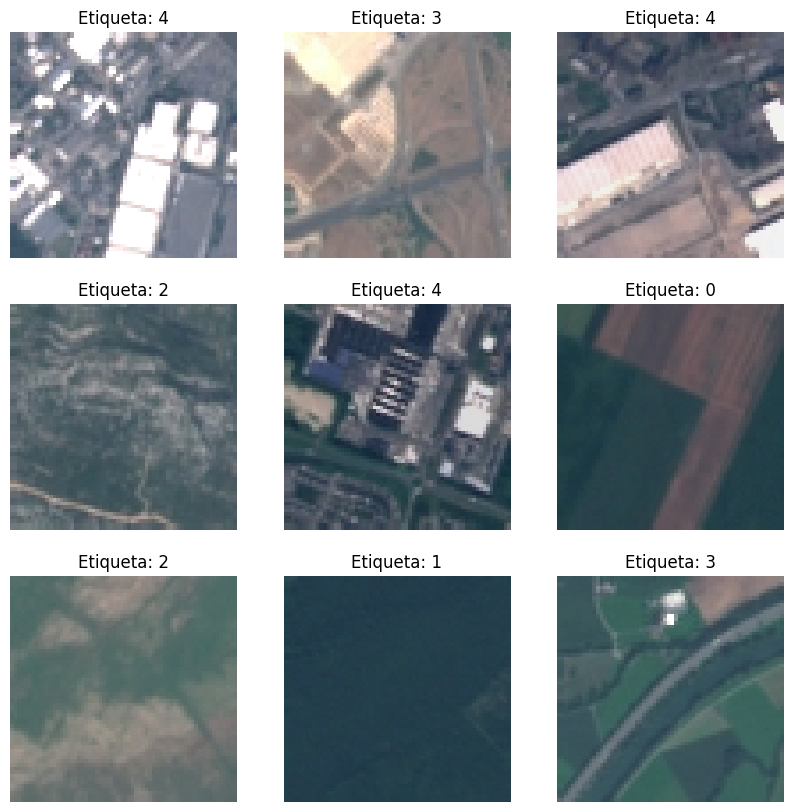

In [17]:
# Tomar exactamente 1 batch (por ejemplo, 32 imágenes con sus 32 etiquetas) del dataset de entrenamiento
for images, labels in train_dataset.take(1):

    plt.figure(figsize=(10, 10))

    # Mostrar las primeras 9 imágenes de ese batch
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)

        # Convertimos el tensor de TensorFlow a un arreglo de NumPy para graficar
        plt.imshow(images[i].numpy())

        # Mostramos el número de la etiqueta correspondiente
        plt.title(f"Etiqueta: {labels[i].numpy()}")
        plt.axis("off")

    plt.show()

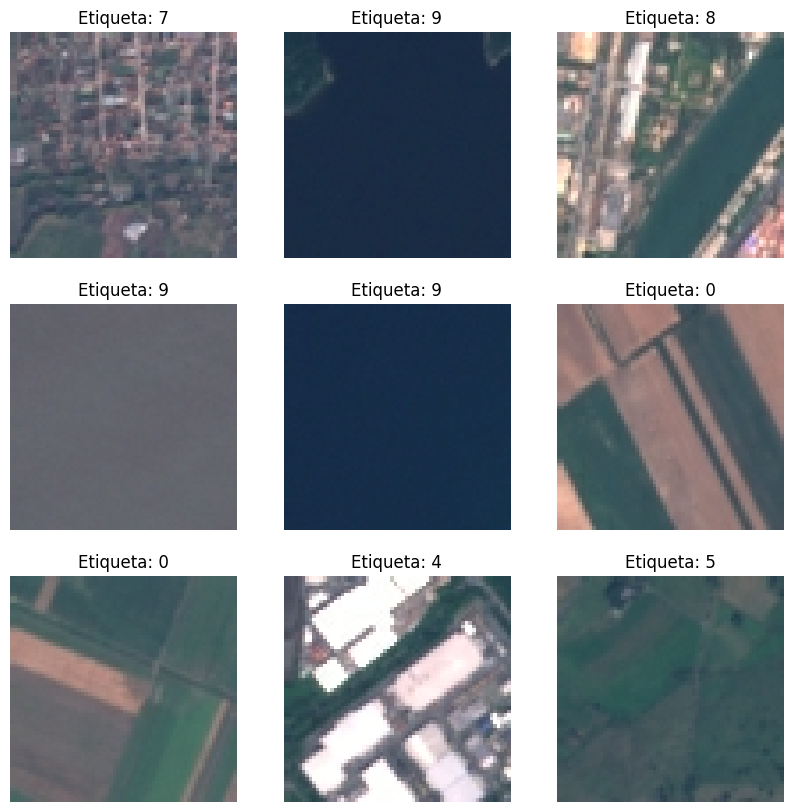

In [18]:
# Tomar exactamente 1 batch (por ejemplo, 32 imágenes con sus 32 etiquetas) del dataset de validación
for images, labels in val_dataset.take(1):

    plt.figure(figsize=(10, 10))

    # Mostrar las primeras 9 imágenes de ese batch
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)

        # Convertimos el tensor de TensorFlow a un arreglo de NumPy para graficar
        plt.imshow(images[i].numpy())

        # Mostramos el número de la etiqueta correspondiente
        plt.title(f"Etiqueta: {labels[i].numpy()}")
        plt.axis("off")

    plt.show()

### **Conclusión del Análisis Exploratorio de Datos (EDA)**

A partir de la exploración inicial del dataset, podemos concluir lo siguiente:
* **Consistencia en el formato:** Todas las imágenes poseen una resolución uniforme de **64x64 píxeles** y cuentan con **3 canales de color (RGB)**, lo que facilita su procesamiento directo en redes neuronales convolucionales sin necesidad de recortes o reescalados drásticos previos.
* **Diversidad de clases:** Se confirmaron **10 categorías bien definidas** que abarcan distintos tipos de terrenos y usos de suelo (zonas urbanas, cuerpos de agua, vegetación, industria, etc.).
* **Calidad de los datos:** Las imágenes se cargaron correctamente desde el formato `TFRecord`, presentando valores de píxeles en el rango estándar `uint8` (0-255).

Esta estructura limpia y uniforme nos indica que el conjunto de datos está listo para proceder a las etapas de división (entrenamiento/prueba) y preprocesamiento (normalización y aumento de datos).

#### **Guardar Datasets Procesados**
Guardar los datasets (con sus transformaciones y preprocesamiento ya aplicados) es muy útil para cargarlos rápidamente en otros notebooks o sesiones futuras.

In [24]:
import os

# Definir la ruta base donde se guardarán los datasets procesados en tu Drive
ruta_guardado = f'{BASE_DIR}/data/processed'
os.makedirs(ruta_guardado, exist_ok=True)

# Guardar cada dataset en su respectiva carpeta
print("Guardando train_dataset...")
train_dataset.save(os.path.join(ruta_guardado, 'train'))

print("Guardando val_dataset...")
val_dataset.save(os.path.join(ruta_guardado, 'val'))

print("Guardando test_dataset...")
test_dataset.save(os.path.join(ruta_guardado, 'test'))

print(f"\n¡Datasets guardados exitosamente en: {ruta_guardado}!")

Guardando train_dataset...
Guardando val_dataset...
Guardando test_dataset...

¡Datasets guardados exitosamente en: /content/drive/MyDrive/ClasificacionTerreno/data/processed!
